# 02 · Activity plots, price checks and the headline USD column

Activity over time in `transfers_started.csv` (rows and USD per hour by chain, per day by bridge and by integrator), the price series of the top tokens with the provided feed and the CoinGecko snapshot overlaid, the checks on `prices.csv`, and the headline USD column: the provided price first, the CoinGecko price where the provided one is missing, flagged by `price_source`.

Inputs: the two provided CSVs and the snapshots under `data/reference/` written by `01_reference_data.ipynb` (`lifi_api_chains.csv`, `lifi_api_tokens_by_chain.csv`, `coingecko_hourly_prices_2026-10-13_to_2026-10-19.csv`). This notebook makes no network call. Every figure uses one fixed colour per source chain, bridge and integrator (§1). Sections that depend on reference data say so; the activity plots in §2 to §5 use the provided feed only.

Sections: 1 setup · 2 rows per hour by chain · 3 USD per hour by chain · 4 rows and USD per day by bridge · 5 integrator activity by day · 6 price series of the top tokens · 7 price checks · 8 the headline USD column and the totals under the two policies.

## 1. Setup

Loading as in `00_explore.ipynb` §1. `amount_usd_provided` is the profile's first USD column (`00_explore.ipynb` §11: `minAmount / 10^decimals × price_usd` from `prices.csv`, no fallback) and is the USD measure of §2 to §6; §8 builds the headline column. The second cell fixes the colours: one per source chain (Okabe-Ito), one per bridge (Paul Tol's muted scheme), and a colour and line style per integrator, the same in every panel and figure where that series appears.

In [1]:
%matplotlib inline
import json
import os
from decimal import Decimal
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

from lifi import paths

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.dpi"] = 100

ROOT = paths.REPO_ROOT                 # the repository root
DATA = paths.data_dir()                # LIFI_DATA_DIR, else data/ in the repository; only the two CSVs are read from it
DATA_LABEL = "LIFI_DATA_DIR" if os.environ.get("LIFI_DATA_DIR") else "data under the repository root"   # printed instead of a path
REF = paths.reference_dir()            # data/reference in the repository, whatever LIFI_DATA_DIR says
FIG = ROOT / "docs" / "figures" / "notebook_02"
FIG.mkdir(parents=True, exist_ok=True)
TRANSFERS, PRICES = DATA / paths.TRANSFERS_FILE, DATA / paths.PRICES_FILE
for f in (TRANSFERS, PRICES):
    if not f.exists():
        raise FileNotFoundError(f"{f.name} is missing from the data directory ({DATA_LABEL}): drop the provided CSV there (see analysis/README.md)")
for f in ("lifi_api_chains.csv", "lifi_api_tokens_by_chain.csv", "coingecko_hourly_prices_2026-10-13_to_2026-10-19.csv"):
    if not (REF / f).exists():
        raise FileNotFoundError(f"{REF.relative_to(ROOT)}/{f} is missing: it is a reference snapshot committed in the repository; restore it with `git checkout -- {REF.relative_to(ROOT)}/{f}` (see data/reference/README.md)")
print("data dir:", DATA_LABEL, "| reference snapshots:", REF.relative_to(ROOT), "in the repository")

ZERO_ADDRESS = "0x0000000000000000000000000000000000000000"
EXPORT_START = pd.Timestamp("2026-10-13 00:00:00", tz="UTC")
EXPORT_END = pd.Timestamp("2026-10-20 00:00:00", tz="UTC")
HOURS = pd.date_range(EXPORT_START, EXPORT_END, freq="h", inclusive="left")
SOURCE_CHAIN_ID = {"ethereum": 1, "arbitrum": 42161, "base": 8453, "optimism": 10, "polygon": 137, "bnb": 56}   # confirmed against lifi_api_chains.csv in 01 §2
CHAINS = ["ethereum", "arbitrum", "base", "optimism", "polygon", "bnb"]


def savefig(fig, name):
    path = FIG / name
    fig.savefig(path, dpi=110, bbox_inches="tight")


raw = pd.read_csv(TRANSFERS)
prices = pd.read_csv(PRICES)
bridge = pd.DataFrame([json.loads(s) for s in raw["bridge_data"]])
tf = pd.concat([raw.drop(columns="bridge_data"), bridge], axis=1)
tf["block_time"] = pd.to_datetime(tf["block_time"], utc=True)
tf["hour"] = tf["block_time"].dt.floor("h")
tf["day"] = tf["block_time"].dt.floor("D")
prices["hour"] = pd.to_datetime(prices["hour"], utc=True)

chains = pd.read_csv(REF / "lifi_api_chains.csv", dtype={"key": str, "native_address": str, "diamondAddress": str})
tokens = pd.read_csv(REF / "lifi_api_tokens_by_chain.csv", dtype={"address": str, "symbol": str, "name": str, "coinKey": str, "priceUSD": str, "verificationStatus": str, "tags": str, "fetched_via": str})
tokens["address_lc"] = tokens["address"].str.lower()
prices_cg = pd.read_csv(REF / "coingecko_hourly_prices_2026-10-13_to_2026-10-19.csv", dtype={"token_address": str})
prices_cg["hour"] = pd.to_datetime(prices_cg["hour"], utc=True)


def token_amount(min_amount, decimals):
    if pd.isna(decimals):
        return float("nan")
    return float(Decimal(int(min_amount)) / Decimal(10) ** int(decimals))


joined = tf.merge(prices[["chain", "token_address", "hour", "symbol", "decimals", "price_usd"]],
                  left_on=["chain", "sendingAssetId", "hour"], right_on=["chain", "token_address", "hour"], how="left")
tf["symbol"] = joined["symbol"]
tf["amount_usd_provided"] = pd.Series([token_amount(a, d) for a, d in zip(joined["minAmount"], joined["decimals"])], index=joined.index) * joined["price_usd"]
TOTAL_PROVIDED = tf["amount_usd_provided"].sum()
print("transfers:", tf.shape, " prices:", prices.shape, " coingecko_hourly_prices_2026-10-13_to_2026-10-19:", prices_cg.shape, " tokens:", tokens.shape, " chains:", chains.shape)
print(f"USD total, provided feed only: {TOTAL_PROVIDED:,.2f} over {int(tf['amount_usd_provided'].notna().sum())} priced rows; unpriced rows: {int(tf['amount_usd_provided'].isna().sum())}")

data dir: LIFI_DATA_DIR | reference snapshots: data/reference in the repository


transfers: (124858, 21)  prices: (40754, 6)  coingecko_hourly_prices_2026-10-13_to_2026-10-19: (41777, 5)  tokens: (35903, 11)  chains: (70, 11)
USD total, provided feed only: 307,935,992.59 over 124477 priced rows; unpriced rows: 381


In [2]:
# Fixed colours: one per source chain, bridge and integrator, the same in every panel and figure where that series appears.
# Source chains: Okabe-Ito, a colour-blind-safe scheme. Bridges: Paul Tol's "muted" scheme, also colour-blind-safe, one colour for each of the nine bridges §4 plots.
# Integrators: §5 plots sixteen strings, more than any colour-blind-safe categorical scheme holds, so each gets a (colour, line style) pair from eight "muted"
# colours crossed with solid and dashed. The four strings in both §5 panels are solid; within a panel no two strings share both colour and style.
CHAIN_COLOURS = {"ethereum": "#000000", "arbitrum": "#56B4E9", "base": "#0072B2", "optimism": "#D55E00", "polygon": "#CC79A7", "bnb": "#E69F00"}
BRIDGE_COLOURS = {"across": "#332288", "relaydepository": "#CC6677", "lifiIntents": "#117733", "layerswap": "#88CCEE", "mayan": "#882255",
                  "polymerStandard": "#44AA99", "gasZipBridge": "#DDCC77", "near": "#AA4499", "glacis": "#999933"}
MUTED8 = ["#332288", "#88CCEE", "#44AA99", "#117733", "#999933", "#CC6677", "#882255", "#AA4499"]
INTEGRATOR_STYLES = {   # string: (colour, line style)
    "jumper.exchange": (MUTED8[0], "-"), "_binancewallet": (MUTED8[1], "-"), "rabbykmsv2": (MUTED8[2], "-"), "Cow": (MUTED8[3], "-"),
    "metamask-bridge": (MUTED8[4], "-"), "base-app": (MUTED8[5], "-"), "phantom": (MUTED8[6], "-"), "lifi-api": (MUTED8[7], "-"), "tangem": (MUTED8[0], "--"), "bitget": (MUTED8[1], "--"),
    "_arbitrum": (MUTED8[4], "--"), "Pharos-Bridge": (MUTED8[5], "--"), "jumperadvanced": (MUTED8[2], "--"), "USDai": (MUTED8[6], "--"), "HashPort-Wallet-Prod": (MUTED8[7], "--"), "oku.trade": (MUTED8[3], "--"),
}
assert set(CHAIN_COLOURS) == set(CHAINS) and len(set(CHAIN_COLOURS.values())) == len(CHAIN_COLOURS)
assert len(set(BRIDGE_COLOURS.values())) == len(BRIDGE_COLOURS) and len(set(INTEGRATOR_STYLES.values())) == len(INTEGRATOR_STYLES)
print("chain colours:", CHAIN_COLOURS)

chain colours: {'ethereum': '#000000', 'arbitrum': '#56B4E9', 'base': '#0072B2', 'optimism': '#D55E00', 'polygon': '#CC79A7', 'bnb': '#E69F00'}


## 2. Rows per hour by chain

One panel per source chain on the same time axis, all 168 hours (an hour with no row shows as zero). The table flags hours below 30% or above 300% of the chain's median hour (provided data only).

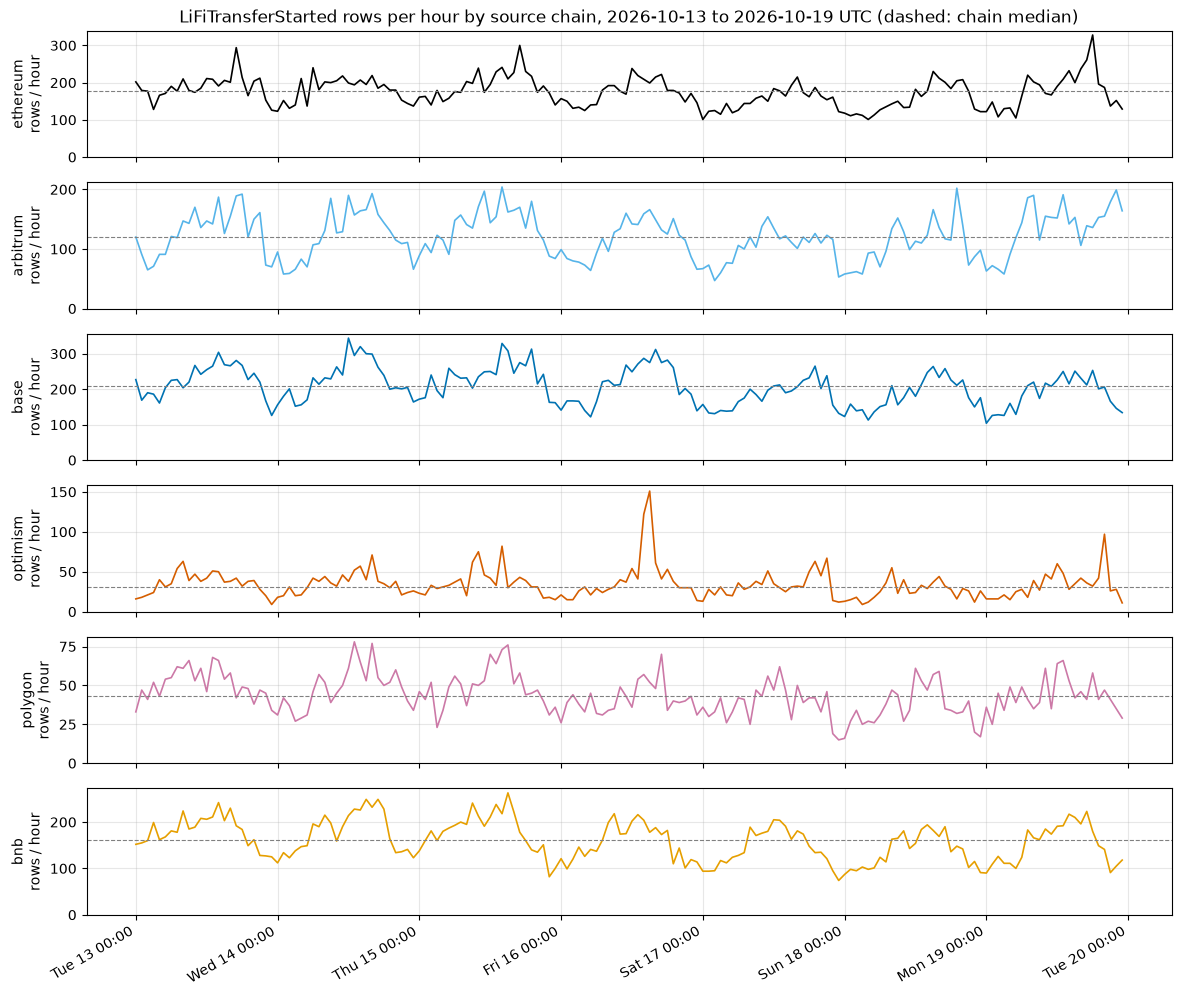

In [3]:
rows_h = tf.groupby(["hour", "chain"]).size().unstack("chain").reindex(HOURS).fillna(0).astype(int)[CHAINS]
fig, axes = plt.subplots(len(CHAINS), 1, figsize=(14, 13), sharex=True)
for ax, c in zip(axes, CHAINS):
    ax.plot(rows_h.index, rows_h[c], lw=1.2, color=CHAIN_COLOURS[c])
    ax.axhline(rows_h[c].median(), color="grey", lw=0.8, ls="--")
    ax.set_ylabel(f"{c}\nrows / hour")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
axes[0].set_title("LiFiTransferStarted rows per hour by source chain, 2026-10-13 to 2026-10-19 UTC (dashed: chain median)")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %H:%M"))
fig.autofmt_xdate()
savefig(fig, "02_s2_rows_per_hour_by_chain.png")
plt.show()

In [4]:
med = rows_h.median()
summary = pd.DataFrame({"median_hour": med, "min_hour": rows_h.min(), "min_at": rows_h.idxmin(), "max_hour": rows_h.max(), "max_at": rows_h.idxmax(), "zero_hours": (rows_h == 0).sum()})
display(summary)
flags = []
for c in CHAINS:
    for h, v in rows_h[c].items():
        if v < 0.3 * med[c] or v > 3 * med[c]:
            flags.append({"chain": c, "hour": h, "rows": int(v), "median": med[c], "ratio": round(v / med[c], 2), "kind": "dip" if v < med[c] else "spike"})
flags = pd.DataFrame(flags).sort_values(["chain", "hour"]) if flags else pd.DataFrame(columns=["chain", "hour", "rows", "median", "ratio", "kind"])
print("flagged hours:", len(flags), " by chain and kind:", flags.groupby(["chain", "kind"]).size().to_dict() if len(flags) else {})
display(flags)
# All chains together: the quietest and busiest hours, and hour-over-hour drops larger than 50%
tot = rows_h.sum(axis=1)
print("all chains, rows per hour: median", tot.median(), " min", tot.min(), "at", tot.idxmin(), " max", tot.max(), "at", tot.idxmax())
drops = (tot / tot.shift(1) - 1)
display(drops[drops < -0.5].to_frame("change_vs_previous_hour").round(3))

,median_hour,min_hour,min_at,max_hour,max_at,zero_hours
chain,,,,,,
ethereum,176.5,101,2026-10-17 00:00:00+00:00,328,2026-10-19 18:00:00+00:00,0
arbitrum,120.5,47,2026-10-17 02:00:00+00:00,204,2026-10-15 14:00:00+00:00,0
base,208.5,104,2026-10-19 00:00:00+00:00,344,2026-10-14 12:00:00+00:00,0
optimism,31.0,9,2026-10-13 23:00:00+00:00,151,2026-10-16 15:00:00+00:00,0
polygon,43.0,15,2026-10-17 23:00:00+00:00,78,2026-10-14 13:00:00+00:00,0
bnb,162.0,74,2026-10-17 23:00:00+00:00,263,2026-10-15 15:00:00+00:00,0


flagged hours: 5  by chain and kind: {('optimism', 'dip'): 2, ('optimism', 'spike'): 3}


,chain,hour,rows,median,ratio,kind
0,optimism,2026-10-13 23:00:00+00:00,9,31.0,0.29,dip
1,optimism,2026-10-16 14:00:00+00:00,122,31.0,3.94,spike
2,optimism,2026-10-16 15:00:00+00:00,151,31.0,4.87,spike
3,optimism,2026-10-18 03:00:00+00:00,9,31.0,0.29,dip
4,optimism,2026-10-19 20:00:00+00:00,97,31.0,3.13,spike


all chains, rows per hour: median 751.0  min 408 at 2026-10-17 23:00:00+00:00  max 1147 at 2026-10-15 14:00:00+00:00


,change_vs_previous_hour


In [5]:
# Hours flagged as spikes: what drove them (the top integrator and bridge inside the hour).
if len(flags[flags["kind"] == "spike"]):
    out = []
    for r in flags[flags["kind"] == "spike"].itertuples():
        sub = tf[(tf["chain"] == r.chain) & (tf["hour"] == r.hour)]
        out.append({"chain": r.chain, "hour": r.hour, "rows": r.rows, "top_integrator": sub["integrator"].value_counts().index[0], "its_rows": int(sub["integrator"].value_counts().iloc[0]),
                    "top_bridge": sub["bridge"].value_counts().index[0], "distinct_tx_from": sub["tx_from"].nunique(), "usd_provided": round(sub["amount_usd_provided"].sum(), 2)})
    display(pd.DataFrame(out))

,chain,hour,rows,top_integrator,its_rows,top_bridge,distinct_tx_from,usd_provided
0,optimism,2026-10-16 14:00:00+00:00,122,jumper.exchange,108,relaydepository,119,25901.64
1,optimism,2026-10-16 15:00:00+00:00,151,jumper.exchange,132,relaydepository,141,31908.66
2,optimism,2026-10-19 20:00:00+00:00,97,jumper.exchange,86,relaydepository,96,21711.47


## 3. USD per hour by chain

`amount_usd_provided` summed per hour and chain, one panel per chain. The table names the three largest hours per chain with the single largest row inside each, because the profile found the total driven by a few transfers above $1M.

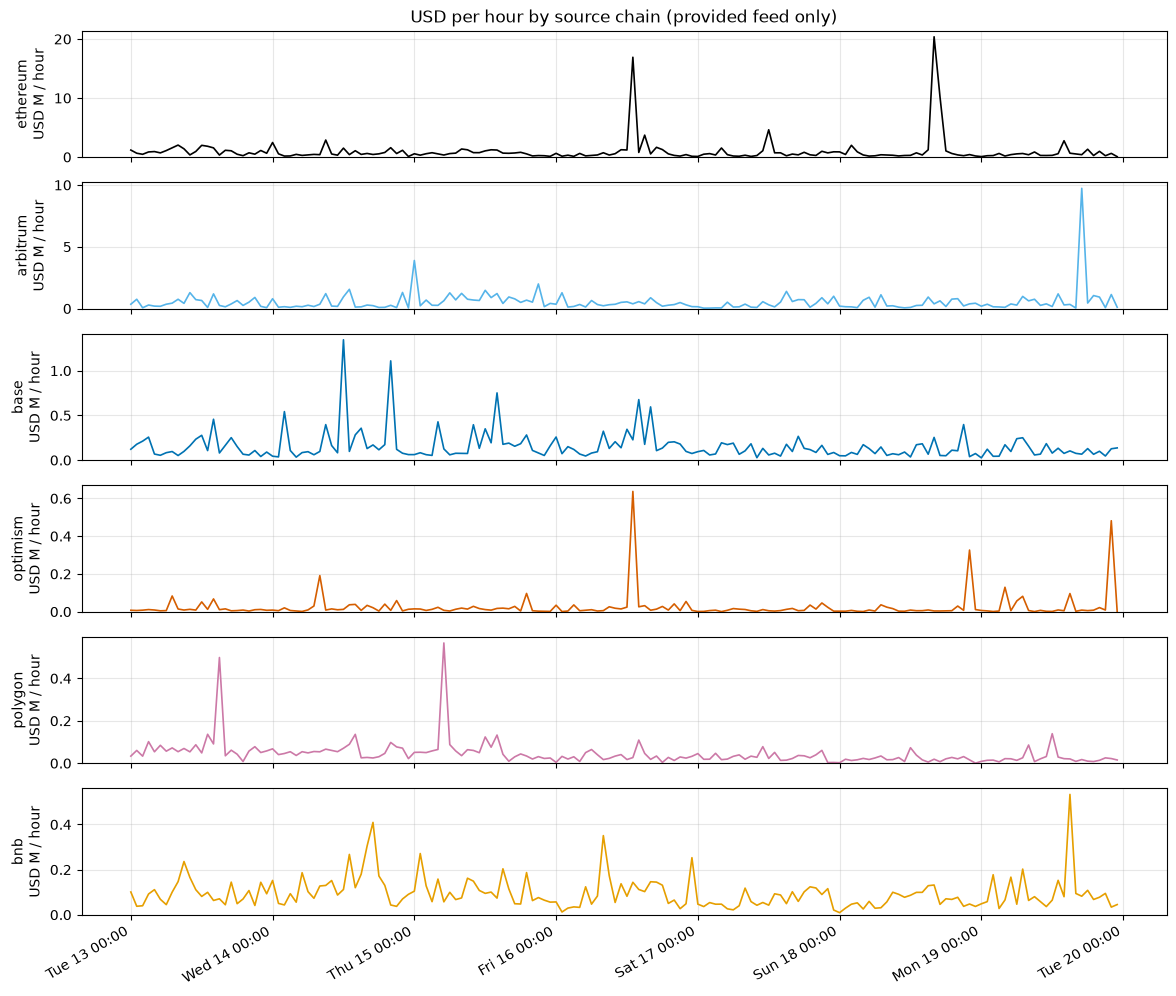

,chain,hour,usd_hour,share_of_chain_usd,rows,largest_row_usd,largest_row_share_of_hour,its_integrator,its_bridge,its_symbol,its_destination
0,ethereum,2026-10-18 16:00:00+00:00,20384911.33,0.1246,212,10002421.67,0.4907,_arbitrum,polymerStandard,USDC,42161
1,ethereum,2026-10-16 13:00:00+00:00,16914864.28,0.1034,219,10000569.17,0.5912,Pharos-Bridge,polymerStandard,USDC,1672
2,ethereum,2026-10-18 17:00:00+00:00,10192798.32,0.0623,201,9521501.02,0.9341,_arbitrum,polymerStandard,USDC,42161
3,arbitrum,2026-10-19 17:00:00+00:00,9732315.63,0.1079,139,9520869.56,0.9783,_arbitrum,polymerStandard,USDC,1
4,arbitrum,2026-10-15 00:00:00+00:00,3891452.38,0.0431,89,2013311.27,0.5174,jumper.exchange,glacis,PYUSD,1
5,arbitrum,2026-10-15 21:00:00+00:00,1994861.92,0.0221,115,1449649.19,0.7267,USDai,glacis,PYUSD,1
6,base,2026-10-14 12:00:00+00:00,1345554.31,0.0513,344,738925.14,0.5492,_binancewallet,polymerStandard,USDC,1672
7,base,2026-10-14 20:00:00+00:00,1109736.16,0.0423,204,500048.58,0.4506,jumperadvanced,polymerStandard,USDC,1
8,base,2026-10-15 14:00:00+00:00,751690.24,0.0287,329,500066.37,0.6653,jumper.exchange,polymerStandard,USDC,42161
9,optimism,2026-10-16 13:00:00+00:00,637199.67,0.1536,41,534083.00,0.8382,jumper.exchange,relaydepository,USDC,1151111081099710


hour-level concentration: share of all USD in the top 5 hours of 168: 0.2137


In [6]:
usd_h = tf.groupby(["hour", "chain"])["amount_usd_provided"].sum().unstack("chain").reindex(HOURS).fillna(0)[CHAINS]
fig, axes = plt.subplots(len(CHAINS), 1, figsize=(14, 13), sharex=True)
for ax, c in zip(axes, CHAINS):
    ax.plot(usd_h.index, usd_h[c] / 1e6, lw=1.2, color=CHAIN_COLOURS[c])
    ax.set_ylabel(f"{c}\nUSD M / hour")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
axes[0].set_title("USD per hour by source chain (provided feed only)")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %H:%M"))
fig.autofmt_xdate()
savefig(fig, "02_s3_usd_per_hour_by_chain.png")
plt.show()
top_hours = []
for c in CHAINS:
    for h in usd_h[c].nlargest(3).index:
        sub = tf[(tf["chain"] == c) & (tf["hour"] == h)]
        big = sub.loc[sub["amount_usd_provided"].idxmax()]
        top_hours.append({"chain": c, "hour": h, "usd_hour": round(usd_h.loc[h, c], 2), "share_of_chain_usd": round(usd_h.loc[h, c] / usd_h[c].sum(), 4), "rows": len(sub),
                          "largest_row_usd": round(big["amount_usd_provided"], 2), "largest_row_share_of_hour": round(big["amount_usd_provided"] / usd_h.loc[h, c], 4),
                          "its_integrator": big["integrator"], "its_bridge": big["bridge"], "its_symbol": big["symbol"], "its_destination": big["destinationChainId"]})
display(pd.DataFrame(top_hours))
print("hour-level concentration: share of all USD in the top 5 hours of 168:", round(tf.groupby("hour")["amount_usd_provided"].sum().nlargest(5).sum() / TOTAL_PROVIDED, 4))

## 4. Rows and USD per day by bridge

The eight bridges with the most rows (rows per day) and the eight with the most USD (USD per day); the tables give the daily values and the largest day-over-day change per bridge.

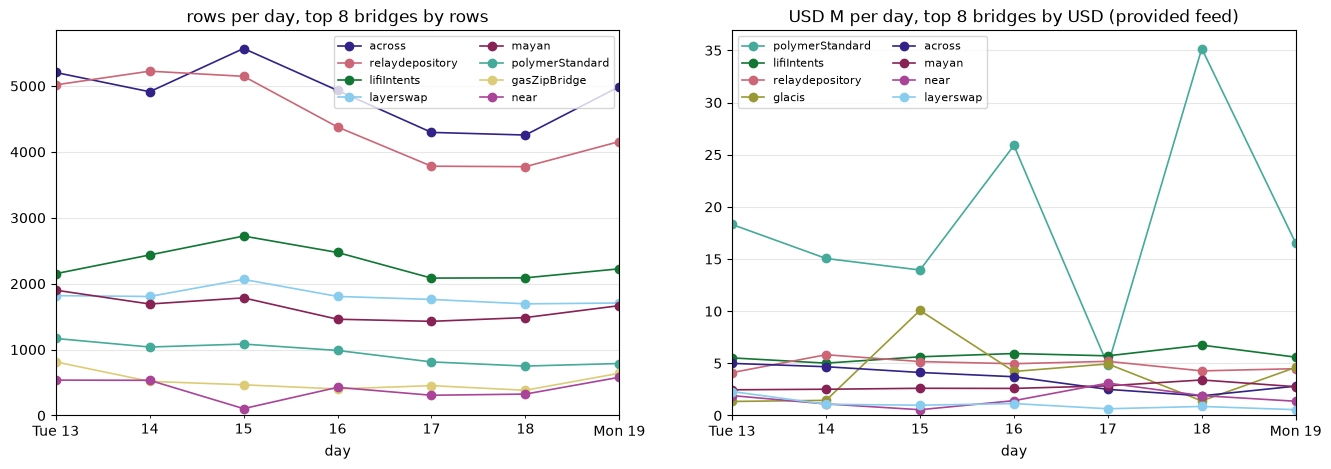

day,2026-10-13 00:00:00+00:00,2026-10-14 00:00:00+00:00,2026-10-15 00:00:00+00:00,2026-10-16 00:00:00+00:00,2026-10-17 00:00:00+00:00,2026-10-18 00:00:00+00:00,2026-10-19 00:00:00+00:00
bridge,,,,,,,
across,5205,4913,5569,4933,4296,4256,4991
relaydepository,5017,5225,5147,4378,3783,3776,4157
lifiIntents,2152,2436,2723,2474,2085,2089,2226
layerswap,1819,1806,2065,1807,1761,1694,1707
mayan,1902,1692,1785,1461,1429,1486,1667
polymerStandard,1169,1039,1084,987,813,750,789
gasZipBridge,814,518,466,403,453,383,641
near,537,534,104,427,307,325,580


day,2026-10-13 00:00:00+00:00,2026-10-14 00:00:00+00:00,2026-10-15 00:00:00+00:00,2026-10-16 00:00:00+00:00,2026-10-17 00:00:00+00:00,2026-10-18 00:00:00+00:00,2026-10-19 00:00:00+00:00
bridge,,,,,,,
polymerStandard,18311605.0,15052686.0,13946014.0,25885845.0,4814127.0,35174054.0,16517963.0
lifiIntents,5522167.0,5019692.0,5626562.0,5940857.0,5719391.0,6746061.0,5592440.0
relaydepository,4112544.0,5824195.0,5170170.0,4963844.0,5191769.0,4276316.0,4486887.0
glacis,1345600.0,1451549.0,10072823.0,4220467.0,4944063.0,1401573.0,4611111.0
across,4996609.0,4675274.0,4124781.0,3716259.0,2505946.0,1886354.0,2812644.0
mayan,2463449.0,2516720.0,2607745.0,2595707.0,2843557.0,3405907.0,2760899.0
near,1908290.0,1110033.0,554382.0,1420505.0,3105192.0,1905320.0,1365741.0
layerswap,2297810.0,1079949.0,984880.0,1145651.0,645178.0,867684.0,556818.0


largest day-over-day change in rows per bridge:


,max_rise,on,max_fall,on_
bridge,,,,
across,0.173,2026-10-19 00:00:00+00:00,-0.129,2026-10-17 00:00:00+00:00
relaydepository,0.101,2026-10-19 00:00:00+00:00,-0.149,2026-10-16 00:00:00+00:00
lifiIntents,0.132,2026-10-14 00:00:00+00:00,-0.157,2026-10-17 00:00:00+00:00
layerswap,0.143,2026-10-15 00:00:00+00:00,-0.125,2026-10-16 00:00:00+00:00
mayan,0.122,2026-10-19 00:00:00+00:00,-0.182,2026-10-16 00:00:00+00:00
polymerStandard,0.052,2026-10-19 00:00:00+00:00,-0.176,2026-10-17 00:00:00+00:00
gasZipBridge,0.674,2026-10-19 00:00:00+00:00,-0.364,2026-10-14 00:00:00+00:00
near,3.106,2026-10-16 00:00:00+00:00,-0.805,2026-10-15 00:00:00+00:00


In [7]:
top_b_rows = tf["bridge"].value_counts().head(8).index.tolist()
top_b_usd = tf.groupby("bridge")["amount_usd_provided"].sum().nlargest(8).index.tolist()
assert set(top_b_rows) | set(top_b_usd) <= set(BRIDGE_COLOURS), sorted((set(top_b_rows) | set(top_b_usd)) - set(BRIDGE_COLOURS))
rows_d = tf[tf["bridge"].isin(top_b_rows)].groupby(["day", "bridge"]).size().unstack("bridge").fillna(0).astype(int)[top_b_rows]
usd_d = tf[tf["bridge"].isin(top_b_usd)].groupby(["day", "bridge"])["amount_usd_provided"].sum().unstack("bridge").fillna(0)[top_b_usd]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
rows_d.plot(ax=axes[0], marker="o", lw=1.2, color=[BRIDGE_COLOURS[b] for b in rows_d.columns])
axes[0].set_title("rows per day, top 8 bridges by rows")
axes[0].set_ylim(bottom=0)
(usd_d / 1e6).plot(ax=axes[1], marker="o", lw=1.2, color=[BRIDGE_COLOURS[b] for b in usd_d.columns])
axes[1].set_title("USD M per day, top 8 bridges by USD (provided feed)")
axes[1].set_ylim(bottom=0)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, ncol=2)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
savefig(fig, "02_s4_bridge_daily.png")
plt.show()
display(rows_d.T)
display(usd_d.round(0).T)
chg = (rows_d / rows_d.shift(1) - 1)
print("largest day-over-day change in rows per bridge:")
display(pd.DataFrame({"max_rise": chg.max().round(3), "on": chg.idxmax(), "max_fall": chg.min().round(3), "on_": chg.idxmin()}))

## 5. Integrator activity by day

The ten integrator strings with the most rows (rows per day), the ten with the most USD (USD per day), and the number of distinct integrator strings active each day. Raw strings, no family grouping: the active-integrator definition is in `task_1.md`.

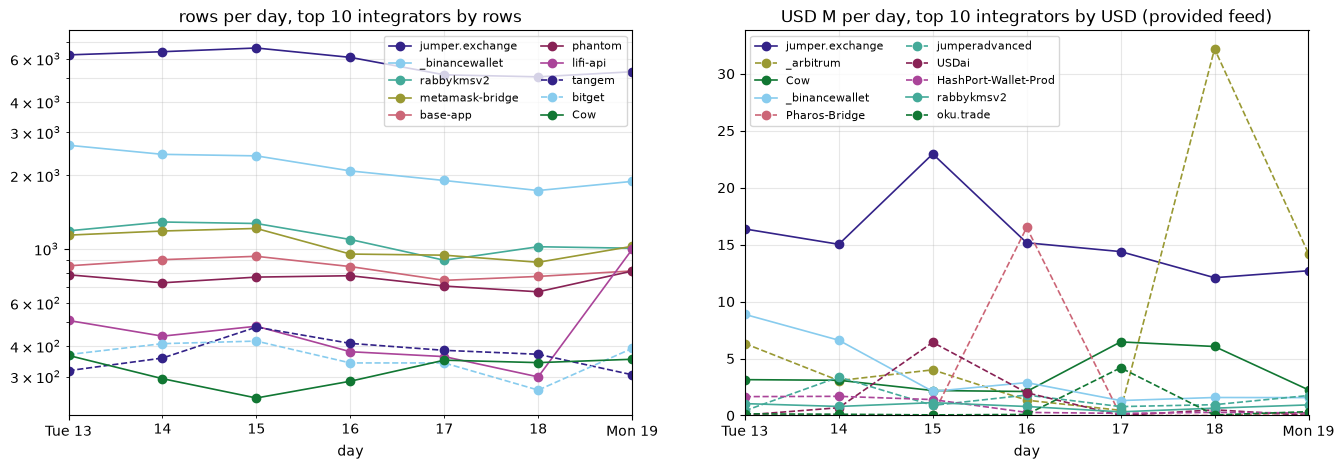

day,2026-10-13 00:00:00+00:00,2026-10-14 00:00:00+00:00,2026-10-15 00:00:00+00:00,2026-10-16 00:00:00+00:00,2026-10-17 00:00:00+00:00,2026-10-18 00:00:00+00:00,2026-10-19 00:00:00+00:00
integrator,,,,,,,
jumper.exchange,6227,6417,6645,6083,5161,5063,5312
_binancewallet,2656,2438,2403,2085,1905,1733,1889
rabbykmsv2,1185,1288,1270,1092,898,1020,1006
metamask-bridge,1138,1183,1212,952,942,881,1024
base-app,852,903,932,846,743,771,812
phantom,783,726,766,776,704,667,811
lifi-api,509,439,482,379,362,299,995
tangem,317,357,478,410,384,370,305
bitget,369,409,419,341,341,264,391


day,2026-10-13 00:00:00+00:00,2026-10-14 00:00:00+00:00,2026-10-15 00:00:00+00:00,2026-10-16 00:00:00+00:00,2026-10-17 00:00:00+00:00,2026-10-18 00:00:00+00:00,2026-10-19 00:00:00+00:00
integrator,,,,,,,
jumper.exchange,16376442.0,15030136.0,22962890.0,15162953.0,14389608.0,12097173.0,12708091.0
_arbitrum,6318484.0,3063659.0,4008908.0,1343831.0,454494.0,32189618.0,14214663.0
Cow,3147332.0,3091586.0,2193653.0,2105813.0,6460642.0,6057654.0,2251044.0
_binancewallet,8877172.0,6608443.0,2113038.0,2887491.0,1311230.0,1580074.0,1568497.0
Pharos-Bridge,31534.0,29.0,619.0,16505985.0,2129.0,401.0,249848.0
jumperadvanced,415333.0,3377658.0,887231.0,1794424.0,782019.0,950089.0,1754991.0
USDai,42074.0,683258.0,6422450.0,2000580.0,1674.0,500151.0,6698.0
HashPort-Wallet-Prod,1657412.0,1682452.0,1397161.0,269343.0,188864.0,272469.0,225777.0
rabbykmsv2,1042556.0,794006.0,1126594.0,789888.0,323663.0,643774.0,931407.0


day,2026-10-13 00:00:00+00:00,2026-10-14 00:00:00+00:00,2026-10-15 00:00:00+00:00,2026-10-16 00:00:00+00:00,2026-10-17 00:00:00+00:00,2026-10-18 00:00:00+00:00,2026-10-19 00:00:00+00:00
distinct_integrators,292,287,274,283,229,234,273
with_10_or_more_rows,87,71,83,84,70,68,80
new_vs_previous_days,292,101,52,53,33,33,34


In [8]:
top_i_rows = tf["integrator"].value_counts().head(10).index.tolist()
top_i_usd = tf.groupby("integrator")["amount_usd_provided"].sum().nlargest(10).index.tolist()
assert set(top_i_rows) | set(top_i_usd) <= set(INTEGRATOR_STYLES), sorted((set(top_i_rows) | set(top_i_usd)) - set(INTEGRATOR_STYLES))
irows_d = tf[tf["integrator"].isin(top_i_rows)].groupby(["day", "integrator"]).size().unstack("integrator").fillna(0).astype(int)[top_i_rows]
iusd_d = tf[tf["integrator"].isin(top_i_usd)].groupby(["day", "integrator"])["amount_usd_provided"].sum().unstack("integrator").fillna(0)[top_i_usd]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
irows_d.plot(ax=axes[0], marker="o", lw=1.2, color=[INTEGRATOR_STYLES[i][0] for i in irows_d.columns], style=[INTEGRATOR_STYLES[i][1] for i in irows_d.columns])
axes[0].set_title("rows per day, top 10 integrators by rows")
axes[0].set_yscale("log")
(iusd_d / 1e6).plot(ax=axes[1], marker="o", lw=1.2, color=[INTEGRATOR_STYLES[i][0] for i in iusd_d.columns], style=[INTEGRATOR_STYLES[i][1] for i in iusd_d.columns])
axes[1].set_title("USD M per day, top 10 integrators by USD (provided feed)")
axes[1].set_ylim(bottom=0)
for ax, cols in zip(axes, (irows_d.columns, iusd_d.columns)):
    ax.grid(alpha=0.3, which="both")
    ax.legend(ax.get_lines(), list(cols), fontsize=8, ncol=2)   # explicit labels: an automatic legend drops labels that start with "_" (_binancewallet, _arbitrum)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
savefig(fig, "02_s5_integrator_daily.png")
plt.show()
display(irows_d.T)
display(iusd_d.round(0).T)
active = tf.groupby("day")["integrator"].nunique().to_frame("distinct_integrators")
active["with_10_or_more_rows"] = tf.groupby(["day", "integrator"]).size().groupby("day").apply(lambda s: int((s >= 10).sum()))
active["new_vs_previous_days"] = [tf.loc[tf["day"] == d, "integrator"].nunique() - len(set(tf.loc[tf["day"] == d, "integrator"]) & set(tf.loc[tf["day"] < d, "integrator"])) for d in active.index]
display(active.T)

## 6. Price series of the top tokens

The six (chain, token) pairs with the most USD, the provided feed (solid) and the CoinGecko snapshot (dashed; reference data) on the same axis, with hours the provided feed lacks shaded. Then the four tokens the profile found with missing hours (tGBP on arbitrum, strUSD and wM and BTC.b on ethereum), where the CoinGecko series shows what the gap hides.

usd_provided
chain    sendingAssetId                                          
ethereum 0xa0b86991c6218b36c1d19d4a2e9eb0ce3606eb48  1.151893e+08
arbitrum 0xaf88d065e77c8cc2239327c5edb3a432268e5831  6.017170e+07
base     0x833589fcd6edb6e08f4c7c32d4f71b54bda02913  2.199970e+07
ethereum 0xdac17f958d2ee523a2206206994597c13d831ec7  1.749036e+07
         0x0000000000000000000000000000000000000000  1.534008e+07
arbitrum 0x46850ad61c2b7d64d08c9c754f45254596696984  1.163092e+07

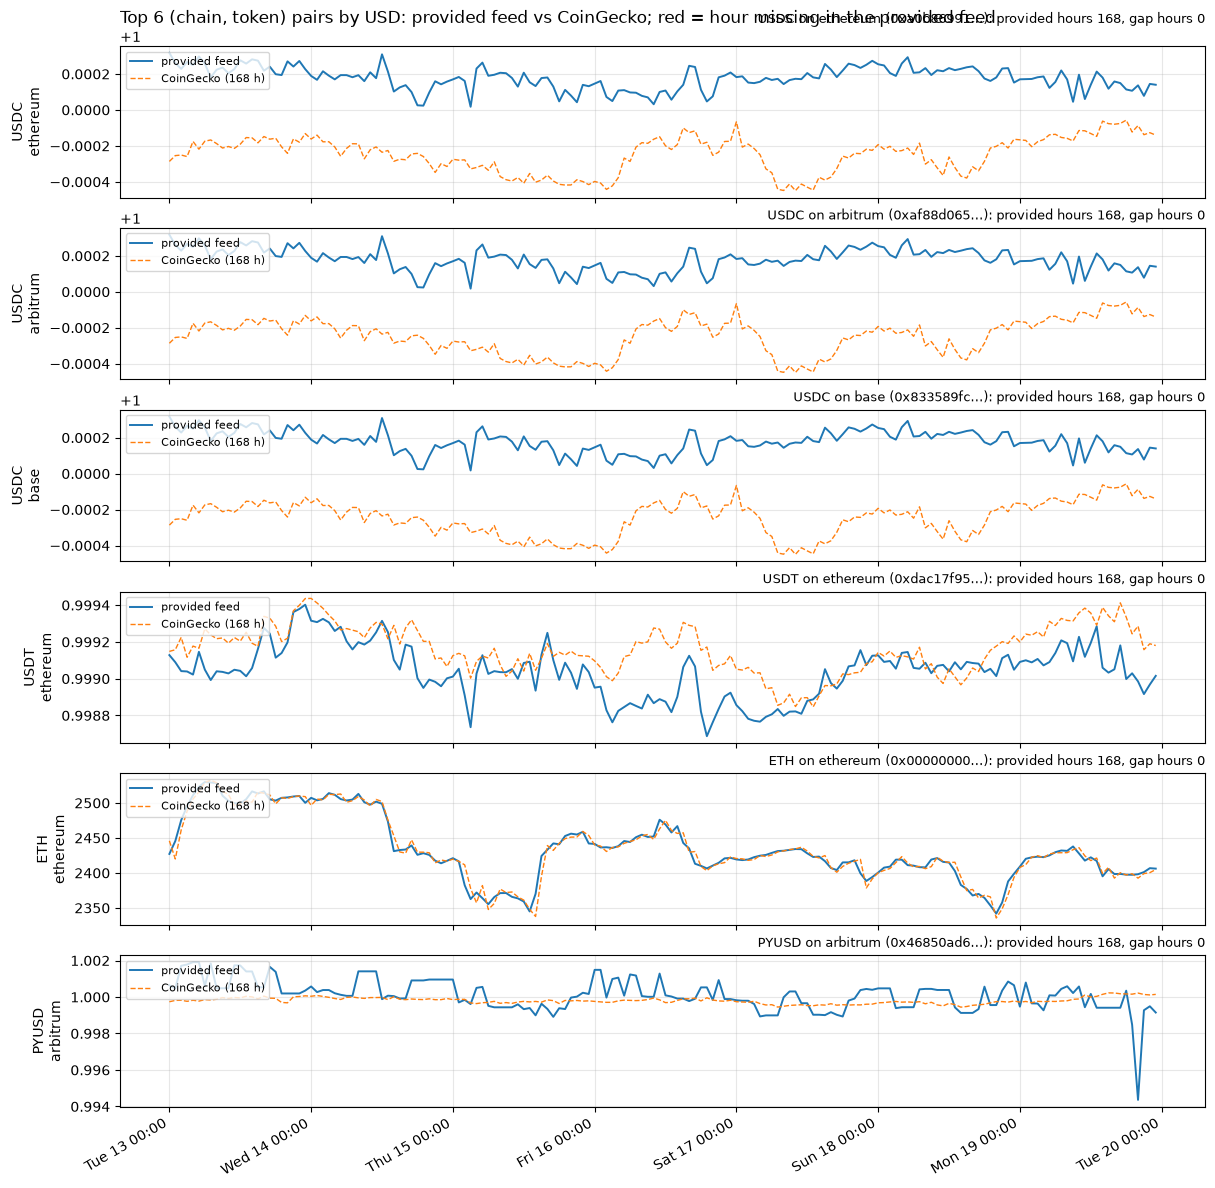

In [9]:
def series_plot(pairs_, name, title):
    fig, axes = plt.subplots(len(pairs_), 1, figsize=(14, 2.6 * len(pairs_)), sharex=True)
    for ax, (c, a) in zip(np.atleast_1d(axes), pairs_):
        p = prices[(prices["chain"] == c) & (prices["token_address"] == a)].set_index("hour").reindex(HOURS)
        g = prices_cg[(prices_cg["chain"] == c) & (prices_cg["token_address"] == a)].set_index("hour").reindex(HOURS)
        sym = prices.loc[(prices["chain"] == c) & (prices["token_address"] == a), "symbol"].iloc[0]
        ax.plot(HOURS, p["price_usd"], lw=1.4, label="provided feed")
        ax.plot(HOURS, g["price_usd"], lw=1.0, ls="--", label=f"CoinGecko ({int(g['price_usd'].notna().sum())} h)")
        for h in HOURS[p["price_usd"].isna()]:
            ax.axvspan(h, h + pd.Timedelta(hours=1), color="red", alpha=0.15, lw=0)
        ax.set_ylabel(f"{sym}\n{c}")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper left")
        gaps = int(p["price_usd"].isna().sum())
        ax.set_title(f"{sym} on {c} ({a[:10]}…): provided hours {168 - gaps}, gap hours {gaps}", fontsize=9, loc="right")
    np.atleast_1d(axes)[0].set_title(title, loc="left")
    np.atleast_1d(axes)[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %H:%M"))
    fig.autofmt_xdate()
    savefig(fig, name)
    plt.show()


top_pairs = tf.groupby(["chain", "sendingAssetId"])["amount_usd_provided"].sum().nlargest(6)
display(top_pairs.to_frame("usd_provided").round(2))
series_plot(list(top_pairs.index), "02_s6_price_series_top_tokens.png", "Top 6 (chain, token) pairs by USD: provided feed vs CoinGecko; red = hour missing in the provided feed")

,chain,token_address,symbol,hours
119,ethereum,0x280839980a7ed0d7717f64125fe241012e5f5815,strUSD,33
174,ethereum,0xb0f70c0bd6fd87dbeb7c10dc692a2a6106817072,BTC.b,104
123,ethereum,0x437cc33344a0b27a429f795ff6b469c72698b291,wM,145
8,arbitrum,0x27f6c8289550fce67f6b50bed1f519966afe5287,tGBP,152


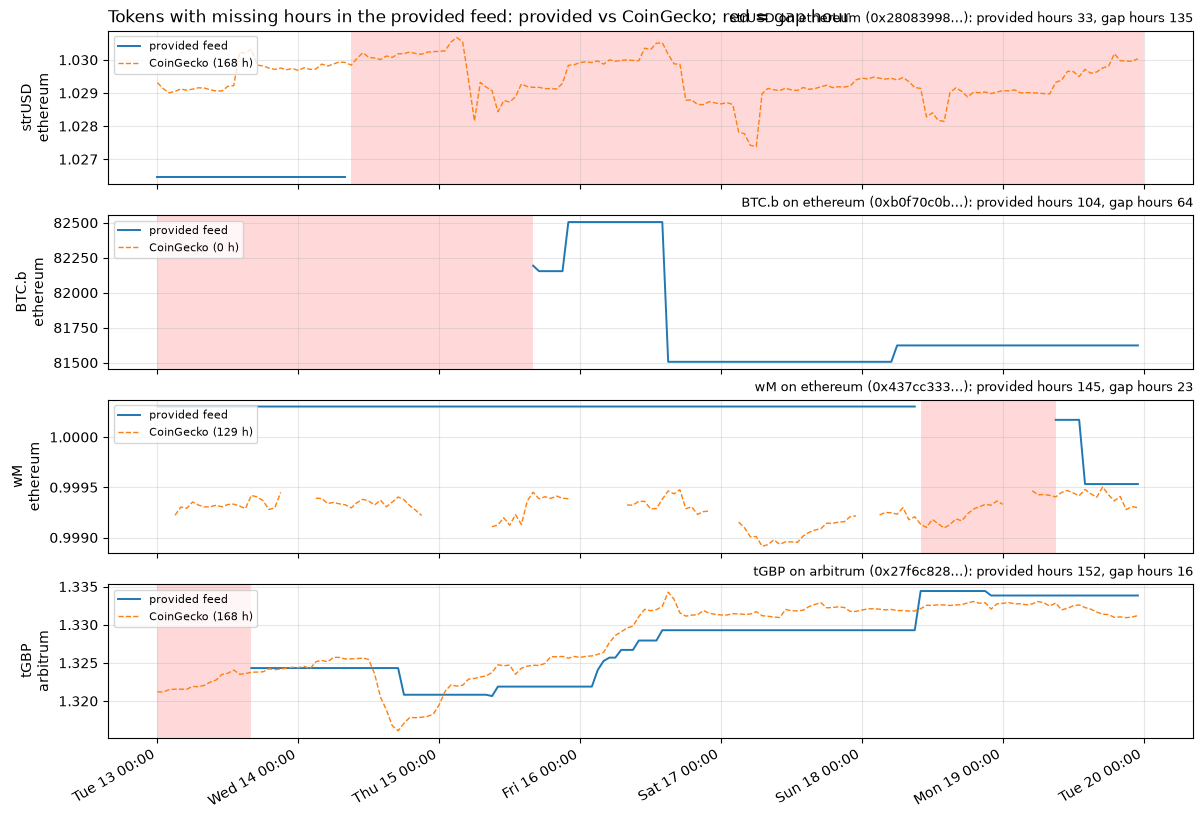

In [10]:
cov = prices.groupby(["chain", "token_address", "symbol"]).size().to_frame("hours").reset_index()
gap_pairs = cov[cov["hours"] < 168].sort_values("hours")
display(gap_pairs)
series_plot(list(zip(gap_pairs["chain"], gap_pairs["token_address"])), "02_s6_price_series_gap_tokens.png", "Tokens with missing hours in the provided feed: provided vs CoinGecko; red = gap hour")

## 7. Price checks

(a) uniqueness of (chain, token_address, hour) in `prices.csv`; (b) duplicates with different prices; (c) hours missing inside the window per (chain, token); (d) deviation of USD stablecoins from 1.00, the set taken by symbol (contains "USD", or DAI, GHO, BOLD, FRAX, LUSD, MIM) restricted to pairs whose median provided price is within 0.90 to 1.10, because `lifi_api_tokens_by_chain.csv` carries no tags; (e) cross-chain consistency per symbol-hour; (f) the provided feed against CoinGecko per token-hour (reference data).

In [11]:
key = ["chain", "token_address", "hour"]
dup = prices.duplicated(key, keep=False)
print("(a) rows:", len(prices), " distinct (chain, token_address, hour):", len(prices.drop_duplicates(key)), " duplicate rows:", int(dup.sum()))
conflicting = prices[dup].groupby(key)["price_usd"].nunique().loc[lambda s: s > 1]
print("(b) duplicated keys with more than one price:", len(conflicting))
print("(a) also: one symbol per (chain, token):", bool((prices.groupby(['chain', 'token_address'])['symbol'].nunique() == 1).all()),
      " one decimals per (chain, token):", bool((prices.groupby(['chain', 'token_address'])['decimals'].nunique() == 1).all()))
cov = prices.groupby(["chain", "token_address", "symbol"])["hour"].agg(hours="size", first="min", last="max").reset_index()
cov["missing_hours"] = 168 - cov["hours"]
cov["missing_inside_span"] = [168 - h - int((EXPORT_START <= f) and (f - EXPORT_START) / pd.Timedelta(hours=1)) - int((EXPORT_END - pd.Timedelta(hours=1) - l) / pd.Timedelta(hours=1)) for h, f, l in zip(cov["hours"], cov["first"], cov["last"])]
print("(c) (chain, token) pairs:", len(cov), " with all 168 hours:", int((cov["hours"] == 168).sum()), " with gaps:", int((cov["hours"] < 168).sum()),
      " total missing token-hours:", int(cov["missing_hours"].sum()), "of", 168 * len(cov))
display(cov[cov["hours"] < 168].sort_values("hours"))
print("(c) transfer rows whose (chain, token) is priced but not at their hour:", int((tf["amount_usd_provided"].isna() & tf.set_index(['chain', 'sendingAssetId']).index.isin(cov.set_index(['chain', 'token_address']).index)).sum()))

(a) rows: 40754  distinct (chain, token_address, hour): 40754  duplicate rows: 0
(b) duplicated keys with more than one price: 0
(a) also: one symbol per (chain, token): True  one decimals per (chain, token): True
(c) (chain, token) pairs: 244  with all 168 hours: 240  with gaps: 4  total missing token-hours: 238 of 40992


,chain,token_address,symbol,hours,first,last,missing_hours,missing_inside_span
119,ethereum,0x280839980a7ed0d7717f64125fe241012e5f5815,strUSD,33,2026-10-13 00:00:00+00:00,2026-10-14 08:00:00+00:00,135,0
174,ethereum,0xb0f70c0bd6fd87dbeb7c10dc692a2a6106817072,BTC.b,104,2026-10-15 16:00:00+00:00,2026-10-19 23:00:00+00:00,64,0
123,ethereum,0x437cc33344a0b27a429f795ff6b469c72698b291,wM,145,2026-10-13 00:00:00+00:00,2026-10-19 23:00:00+00:00,23,23
8,arbitrum,0x27f6c8289550fce67f6b50bed1f519966afe5287,tGBP,152,2026-10-13 16:00:00+00:00,2026-10-19 23:00:00+00:00,16,0


(c) transfer rows whose (chain, token) is priced but not at their hour: 1


In [12]:
# (d) stablecoin deviation from 1.00. lifi_api_tokens_by_chain.csv carries no tags (the bulk /v1/tokens list returns none, checked in 01 §3), so the set is symbol-based:
# a prices.csv symbol containing "USD" (any case) or one of DAI, GHO, BOLD, FRAX, LUSD, MIM, restricted to pairs whose median provided price is within 0.90-1.10.
pm = prices.groupby(["chain", "token_address", "symbol", "decimals"])["price_usd"].agg(median_price="median", min_price="min", max_price="max", hours="size").reset_index()
pm["usd_symbol"] = pm["symbol"].str.contains("USD", case=False) | pm["symbol"].isin(["DAI", "GHO", "BOLD", "FRAX", "LUSD", "MIM"])
cand = pm[pm["usd_symbol"]].copy()
usd_stable = cand[cand["median_price"].between(0.9, 1.1)]
print("pairs with a USD-like symbol:", len(cand), " of which median price within 0.90-1.10 (treated as USD-pegged):", len(usd_stable), " symbols:", sorted(usd_stable["symbol"].unique()))
print("USD-like symbol but median price outside 0.90-1.10 (excluded):", cand[~cand["median_price"].between(0.9, 1.1)][["chain", "symbol", "median_price"]].round(4).to_dict("records"))
sp = prices.merge(usd_stable[["chain", "token_address"]], on=["chain", "token_address"])
sp["dev"] = sp["price_usd"] - 1
print(f"USD-stable token-hours: {len(sp)}; |dev| > 0.5%: {int((sp['dev'].abs() > 0.005).sum())}; > 1%: {int((sp['dev'].abs() > 0.01).sum())}; > 5%: {int((sp['dev'].abs() > 0.05).sum())}; "
      f"mean dev {sp['dev'].mean():+.5f}, max {sp['dev'].max():+.5f}, min {sp['dev'].min():+.5f}")
per_tok = sp.groupby(["chain", "symbol", "token_address"])["dev"].agg(hours="size", mean="mean", min="min", max="max", abs_max=lambda s: s.abs().max()).round(5).sort_values("abs_max", ascending=False)
display(per_tok.head(15))
usd_by_pair = tf.groupby(["chain", "sendingAssetId"])["amount_usd_provided"].sum()
print("USD (provided) carried by the USD-pegged set:", round(float(usd_by_pair.reindex(list(zip(usd_stable["chain"], usd_stable["token_address"]))).sum()), 2), "of", round(float(TOTAL_PROVIDED), 2))
print("worst USD-stable token-hours:")
display(sp.assign(abs_dev=sp["dev"].abs()).nlargest(10, "abs_dev")[["chain", "symbol", "token_address", "hour", "price_usd", "dev"]].round({"price_usd": 5, "dev": 5}))

pairs with a USD-like symbol: 53  of which median price within 0.90-1.10 (treated as USD-pegged): 51  symbols: ['AUSD', 'DAI', 'GHO', 'PYUSD', 'RLUSD', 'USD1', 'USDC', 'USDG', 'USDS', 'USDT', 'USDT0', 'USDai', 'USDbC', 'USDe', 'USDf', 'USD₮0', 'apxUSD', 'axlUSDC', 'crvUSD', 'frxUSD', 'oUSDT', 'strUSD']
USD-like symbol but median price outside 0.90-1.10 (excluded): [{'chain': 'arbitrum', 'symbol': 'sUSDai', 'median_price': 1.1162}, {'chain': 'base', 'symbol': 'sUSDai', 'median_price': 1.1163}]
USD-stable token-hours: 8433; |dev| > 0.5%: 195; > 1%: 159; > 5%: 76; mean dev -0.00119, max +0.02645, min -0.10688


hours     mean      min      max  abs_max
chain    symbol token_address                                                                        
base     apxUSD 0xd993935e13851dd7517af10687ec7e5022127228    168 -0.05141 -0.10688 -0.00003  0.10688
ethereum strUSD 0x280839980a7ed0d7717f64125fe241012e5f5815     33  0.02645  0.02645  0.02645  0.02645
arbitrum PYUSD  0x46850ad61c2b7d64d08c9c754f45254596696984    168  0.00011 -0.00564  0.00191  0.00564
base     GHO    0x6bb7a212910682dcfdbd5bcbb3e28fb4e8da10ee    168 -0.00094 -0.00351  0.00528  0.00528
ethereum USDf   0xfa2b947eec368f42195f24f36d2af29f7c24cec2    168 -0.00373 -0.00487 -0.00133  0.00487
base     frxUSD 0xe5020a6d073a794b6e7f05678707de47986fb0b6    168  0.00001 -0.00307  0.00417  0.00417
         oUSDT  0x1217bfe6c773eec6cc4a38b5dc45b92292b6e189    168 -0.00088 -0.00387  0.00048  0.00387
         USD₮0  0x102d758f688a4c1c5a80b116bd945d4455460282    168 -0.00091 -0.00356  0.00022  0.00356
ethereum crvUSD 0xf939e0a03fb07f59a73314e73794be0e57ac1b4e    168 -0.00122 -0.00346  0.00140  0.00346
         frxUSD 0xcacd6fd266af91b8aed52accc382b4e165586e29    168 -0.00009 -0.00296  0.00313  0.00313
optimism USD₮0  0x01bff41798a0bcf287b996046ca68b395dbc1071    168 -0.00091 -0.00150 -0.00043  0.00150
bnb      USD1   0x8d0d000ee44948fc98c9b98a4fa4921476f08b0d    168 -0.00100 -0.00149 -0.00064  0.00149
ethereum USD1   0x8d0d000ee44948fc98c9b98a4fa4921476f08b0d    168 -0.00100 -0.00149 -0.00064  0.00149
arbitrum GHO    0x7dff72693f6a4149b17e7c6314655f6a9f7c8b33    168 -0.00101 -0.00141 -0.00062  0.00141
ethereum GHO    0x40d16fc0246ad3160ccc09b8d0d3a2cd28ae6c2f    168 -0.00101 -0.00141 -0.00062  0.00141

USD (provided) carried by the USD-pegged set: 271065541.78 of 307935992.59
worst USD-stable token-hours:


,chain,symbol,token_address,hour,price_usd,dev
2579,base,apxUSD,0xd993935e13851dd7517af10687ec7e5022127228,2026-10-15 11:00:00+00:00,0.89312,-0.10688
2580,base,apxUSD,0xd993935e13851dd7517af10687ec7e5022127228,2026-10-15 12:00:00+00:00,0.89312,-0.10688
2581,base,apxUSD,0xd993935e13851dd7517af10687ec7e5022127228,2026-10-15 13:00:00+00:00,0.89312,-0.10688
2582,base,apxUSD,0xd993935e13851dd7517af10687ec7e5022127228,2026-10-15 14:00:00+00:00,0.89312,-0.10688
2583,base,apxUSD,0xd993935e13851dd7517af10687ec7e5022127228,2026-10-15 15:00:00+00:00,0.89312,-0.10688
2584,base,apxUSD,0xd993935e13851dd7517af10687ec7e5022127228,2026-10-15 16:00:00+00:00,0.89316,-0.10684
2564,base,apxUSD,0xd993935e13851dd7517af10687ec7e5022127228,2026-10-14 20:00:00+00:00,0.89468,-0.10532
2565,base,apxUSD,0xd993935e13851dd7517af10687ec7e5022127228,2026-10-14 21:00:00+00:00,0.89468,-0.10532
2640,base,apxUSD,0xd993935e13851dd7517af10687ec7e5022127228,2026-10-18 00:00:00+00:00,0.89528,-0.10472
2641,base,apxUSD,0xd993935e13851dd7517af10687ec7e5022127228,2026-10-18 01:00:00+00:00,0.89528,-0.10472


In [13]:
# (e) cross-chain consistency: for each symbol present on more than one (chain, address), the relative spread of price_usd across them per hour
multi = prices.groupby("symbol")["chain"].nunique().loc[lambda s: s > 1].index
x = prices[prices["symbol"].isin(multi)].groupby(["symbol", "hour"])["price_usd"].agg(n="size", lo="min", hi="max", mean="mean").reset_index()
x["spread"] = (x["hi"] - x["lo"]) / x["mean"]
per_sym = x.groupby("symbol").agg(pairs=("n", "max"), hours=("hour", "size"), max_spread=("spread", "max"), mean_spread=("spread", "mean"), hours_over_0_5pct=("spread", lambda s: int((s > 0.005).sum())), hours_over_5pct=("spread", lambda s: int((s > 0.05).sum()))).sort_values("max_spread", ascending=False)
print("symbols on more than one chain:", len(multi), " of which identical in every hour (max spread 0):", int((per_sym["max_spread"] == 0).sum()))
display(per_sym.round(5))
print("worst symbol-hours:")
display(x.nlargest(8, "spread")[["symbol", "hour", "n", "lo", "hi", "spread"]].round({"lo": 5, "hi": 5, "spread": 5}))
print("same symbol on one chain with two addresses (USDC variants), spread per hour between the two:")
v = prices[prices["symbol"] == "USDC"].groupby(["chain", "hour"])["price_usd"].agg(n="size", lo="min", hi="max").reset_index().query("n > 1")
v["spread"] = (v["hi"] - v["lo"]) / v["lo"]
display(v.groupby("chain")["spread"].agg(hours="size", max="max", mean="mean").round(6))

symbols on more than one chain: 43  of which identical in every hour (max spread 0): 16


,pairs,hours,max_spread,mean_spread,hours_over_0_5pct,hours_over_5pct
symbol,,,,,,
EURA,5,168,0.20508,0.05390,165,39
G,3,168,0.19770,0.09941,166,145
WXTZ,2,168,0.15790,0.07083,161,105
SOMI,2,168,0.11794,0.04778,165,73
ZRC,2,168,0.10320,0.03552,151,46
ENA,2,168,0.09783,0.00521,47,1
W,2,168,0.09355,0.02461,146,20
ORDER,2,168,0.09127,0.01401,111,6
L3,4,168,0.08885,0.03003,167,13


worst symbol-hours:


,symbol,hour,n,lo,hi,spread
1176,EURA,2026-10-13 00:00:00+00:00,5,1.11473,1.35312,0.20508
1177,EURA,2026-10-13 01:00:00+00:00,5,1.11598,1.35312,0.20384
1187,EURA,2026-10-13 11:00:00+00:00,5,1.11635,1.35312,0.20346
1178,EURA,2026-10-13 02:00:00+00:00,5,1.11658,1.35312,0.20324
1180,EURA,2026-10-13 04:00:00+00:00,5,1.11688,1.35312,0.20293
1186,EURA,2026-10-13 10:00:00+00:00,5,1.11692,1.35312,0.20289
1179,EURA,2026-10-13 03:00:00+00:00,5,1.11696,1.35312,0.20286
1188,EURA,2026-10-13 12:00:00+00:00,5,1.11715,1.35312,0.20267


same symbol on one chain with two addresses (USDC variants), spread per hour between the two:


,hours,max,mean
chain,,,
arbitrum,168,0.0,0.0
optimism,168,0.0,0.0
polygon,168,0.0,0.0


provided token-hours: 40754; with a CoinGecko price for the same (chain, token, hour): 40095 (0.9838); pairs with any CoinGecko hour: 240 of 244


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
provided / coingecko - 1,40095.0,0.00979,0.20721,-0.95329,-0.07175,-0.01275,-0.00152,0.00028,0.00185,0.01423,0.11867,4.72507


share of token-hours with |rel diff| over 0.1% / 1% / 5% / 20%: [0.6168, 0.1332, 0.0323, 0.0105]
USD (provided) carried by pairs whose median |rel diff| exceeds 1% / 5%: [47461.35, 1147.7] of 307935992.59
pairs whose median |rel diff| exceeds 1%:


hours   median     mean  abs_max  hours_over_1pct  rows  usd_provided
chain    symbol token_address                                                                                                    
ethereum SWEAT  0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35    168  2.51812  2.87716  4.72507              168     3      60.38197
base     ISLAND 0x157a6df6b74f4e5e45af4e4615fde7b49225a662    168 -0.86596 -0.86761  0.95329              168     1       0.00202
ethereum SAHARA 0xfdffb411c4a70aa7c95d5c981a6fb4da867e1111    168  0.02720  0.04842  0.22539              156     1     263.08251
bnb      GAME   0x825459139c897d769339f295e962396c4f9e4a4d    168 -0.09974 -0.06386  0.22138              156     6     973.03128
base     G      0x9c7beba8f6ef6643abd725e45a4e8387ef260649    168  0.08872  0.09957  0.21644              164     8      83.00348
ethereum ZRC    0xfd418e42783382e86ae91e445406600ba144d162    168 -0.01066 -0.00952  0.19369              111    28   11040.04872
polygon  COCA   0x7b12598e3616261df1c05ec28de0d2fb10c1f206    168 -0.01993 -0.01747  0.19182              142     1      49.47089
ethereum WXTZ   0xc9b53ab2679f573e480d01e0f49e2b5cfb7a3eab    168  0.05164  0.05178  0.19175              151     6      31.28230
         SOMI   0x1b0f6590d21dc02b92ad3a7d00f8884dc4f1aed9    168 -0.03896 -0.03498  0.12913              160     5     501.06865
base     apxUSD 0xd993935e13851dd7517af10687ec7e5022127228    168 -0.01670 -0.03892  0.10084               93     2   26154.13447
ethereum BTR    0x6c76de483f1752ac8473e2b4983a873991e70da7    168 -0.01656 -0.01825  0.09957              123     2     197.29046
arbitrum L3     0x46777c76dbbe40fabb2aab99e33ce20058e76c59    168  0.01520  0.01518  0.08855              109     4    1744.08365
bnb      L3     0x46777c76dbbe40fabb2aab99e33ce20058e76c59    168  0.01040  0.01145  0.08185              103    12    4270.73443
base     L3     0x46777c76dbbe40fabb2aab99e33ce20058e76c59    168 -0.01035 -0.00755  0.07182              115    16    2093.12745
ethereum ELON   0x761d38e5ddf6ccf6cf7c55759d5210750b5d60f3    168  0.02326  0.01815  0.06834              137     1       0.60821

pairs by largest single-hour disagreement:


hours   median     mean  abs_max  hours_over_1pct  rows  usd_provided
chain    symbol token_address                                                                                                    
ethereum SWEAT  0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35    168  2.51812  2.87716  4.72507              168     3      60.38197
         GEAR   0xba3335588d9403515223f109edc4eb7269a9ab5d    168  0.00029  0.17160  1.62173               56     1       3.04931
bnb      PUFFER 0x87d00066cf131ff54b72b134a217d5401e5392b6    168 -0.00486  0.00463  1.58770               74     1     324.59983
base     ISLAND 0x157a6df6b74f4e5e45af4e4615fde7b49225a662    168 -0.86596 -0.86761  0.95329              168     1       0.00202
optimism kBTC   0x73e0c0d45e048d25fc26fa3159b0aa04bfa4db98    168 -0.00883 -0.03020  0.49857               72     1      86.35905
bnb      AGT    0x5dbde81fce337ff4bcaaee4ca3466c00aecae274    168  0.00332  0.00556  0.28181               66     1      47.05882
         ZRC    0xdac991621fd8048d9f235324780abd6c3ad26421    168  0.00297  0.00658  0.23831              137    25   14366.76238
ethereum SAHARA 0xfdffb411c4a70aa7c95d5c981a6fb4da867e1111    168  0.02720  0.04842  0.22539              156     1     263.08251
bnb      GAME   0x825459139c897d769339f295e962396c4f9e4a4d    168 -0.09974 -0.06386  0.22138              156     6     973.03128
base     G      0x9c7beba8f6ef6643abd725e45a4e8387ef260649    168  0.08872  0.09957  0.21644              164     8      83.00348
         EURA   0xa61beb4a3d02decb01039e378237032b351125b4    168 -0.00684  0.03235  0.21484              147     2       4.50016
ethereum ZRC    0xfd418e42783382e86ae91e445406600ba144d162    168 -0.01066 -0.00952  0.19369              111    28   11040.04872

worst token-hours:


,chain,symbol,token_address,hour,price_usd,price_cg,rel_diff
29368,ethereum,SWEAT,0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35,2026-10-14 14:00:00+00:00,0.000414,0.000072,4.72507
29369,ethereum,SWEAT,0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35,2026-10-14 15:00:00+00:00,0.000414,0.000074,4.60730
29389,ethereum,SWEAT,0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35,2026-10-15 11:00:00+00:00,0.000413,0.000074,4.58218
29371,ethereum,SWEAT,0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35,2026-10-14 17:00:00+00:00,0.000414,0.000074,4.56146
29382,ethereum,SWEAT,0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35,2026-10-15 04:00:00+00:00,0.000414,0.000075,4.54016
29391,ethereum,SWEAT,0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35,2026-10-15 13:00:00+00:00,0.000412,0.000075,4.52933
29370,ethereum,SWEAT,0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35,2026-10-14 16:00:00+00:00,0.000414,0.000075,4.52654
29367,ethereum,SWEAT,0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35,2026-10-14 13:00:00+00:00,0.000414,0.000075,4.52108
29388,ethereum,SWEAT,0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35,2026-10-15 10:00:00+00:00,0.000413,0.000075,4.51854
29390,ethereum,SWEAT,0xb4b9dc1c77bdbb135ea907fd5a08094d98883a35,2026-10-15 12:00:00+00:00,0.000412,0.000075,4.49270


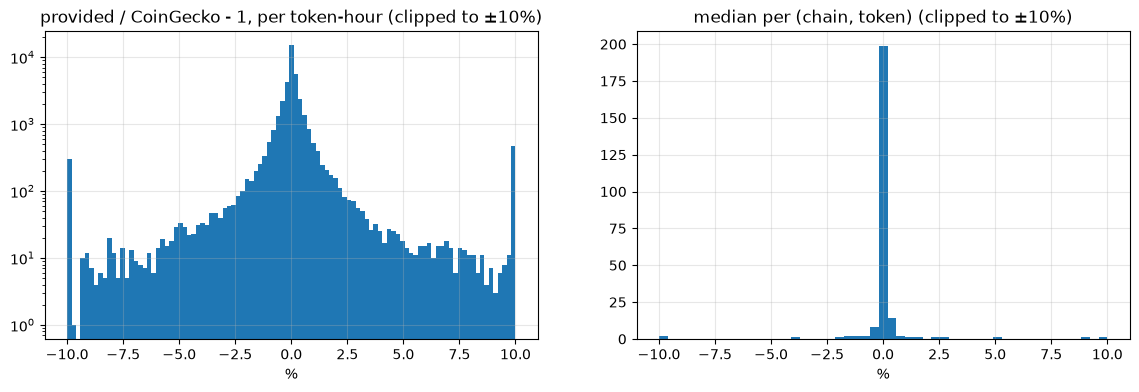

In [14]:
# (f) the provided feed against CoinGecko per token-hour (reference data)
cmp = prices.merge(prices_cg.rename(columns={"price_usd": "price_cg"}), on=["chain", "token_address", "hour"], how="left")
has = cmp["price_cg"].notna()
pairs_cg = cmp[has].groupby(["chain", "token_address"]).size()
print(f"provided token-hours: {len(cmp)}; with a CoinGecko price for the same (chain, token, hour): {int(has.sum())} ({has.mean():.4f}); pairs with any CoinGecko hour: {len(pairs_cg)} of {cmp.groupby(['chain', 'token_address']).ngroups}")
cmp = cmp[has].copy()
cmp["rel_diff"] = cmp["price_usd"] / cmp["price_cg"] - 1
cmp["abs_rel_diff"] = cmp["rel_diff"].abs()
display(cmp["rel_diff"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("provided / coingecko - 1").T.round(5))
print("share of token-hours with |rel diff| over 0.1% / 1% / 5% / 20%:", [round(float((cmp["abs_rel_diff"] > t).mean()), 4) for t in (0.001, 0.01, 0.05, 0.2)])
per_pair = cmp.groupby(["chain", "symbol", "token_address"])["rel_diff"].agg(hours="size", median="median", mean="mean", abs_max=lambda s: s.abs().max(), hours_over_1pct=lambda s: int((s.abs() > 0.01).sum())).sort_values("abs_max", ascending=False)
pair_usd = tf.groupby(["chain", "sendingAssetId"]).agg(rows=("tx_hash", "size"), usd_provided=("amount_usd_provided", "sum"))
pair_usd.index.names = ["chain", "token_address"]
per_pair = per_pair.reset_index().merge(pair_usd.reset_index(), on=["chain", "token_address"], how="left").set_index(["chain", "symbol", "token_address"])
print("USD (provided) carried by pairs whose median |rel diff| exceeds 1% / 5%:", [round(float(per_pair.loc[per_pair["median"].abs() > t, "usd_provided"].sum()), 2) for t in (0.01, 0.05)], "of", round(float(TOTAL_PROVIDED), 2))
print("pairs whose median |rel diff| exceeds 1%:")
display(per_pair[per_pair["median"].abs() > 0.01].round(5))
print("pairs by largest single-hour disagreement:")
display(per_pair.head(12).round(5))
print("worst token-hours:")
display(cmp.nlargest(12, "abs_rel_diff")[["chain", "symbol", "token_address", "hour", "price_usd", "price_cg", "rel_diff"]].round({"price_usd": 6, "price_cg": 6, "rel_diff": 5}))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(cmp["rel_diff"].clip(-0.1, 0.1) * 100, bins=101)
axes[0].set_title("provided / CoinGecko - 1, per token-hour (clipped to ±10%)")
axes[0].set_xlabel("%")
axes[0].set_yscale("log")
axes[1].hist(per_pair["median"].clip(-0.1, 0.1) * 100, bins=51)
axes[1].set_title("median per (chain, token) (clipped to ±10%)")
axes[1].set_xlabel("%")
for ax in axes:
    ax.grid(alpha=0.3)
savefig(fig, "02_s7_provided_vs_coingecko.png")
plt.show()

In [15]:
# The three tokens the profile flagged for large hourly moves: every hour where the provided price is at or beyond a factor of 1.5 from CoinGecko
# in either direction (ratio >= 1.5 or <= 1/1.5), with both prices, and the runs of consecutive such hours (reference data).
WATCH = [("ethereum", "0xba3335588d9403515223f109edc4eb7269a9ab5d", "GEAR"), ("optimism", "0x73e0c0d45e048d25fc26fa3159b0aa04bfa4db98", "kBTC"), ("bnb", "0x87d00066cf131ff54b72b134a217d5401e5392b6", "PUFFER")]
for c, a, sym in WATCH:
    d = cmp[(cmp["chain"] == c) & (cmp["token_address"] == a)].sort_values("hour").copy()
    d["ratio"] = d["price_usd"] / d["price_cg"]
    big = d[(d["ratio"] >= 1.5) | (d["ratio"] <= 1 / 1.5)]
    runs = []
    for h in big["hour"]:
        if runs and h - runs[-1][1] == pd.Timedelta(hours=1):
            runs[-1][1] = h
        else:
            runs.append([h, h])
    print(f"{sym} on {c}: {len(big)} of {len(d)} hours at or beyond 1.5x either way; CoinGecko over the week {d['price_cg'].min():.6g} to {d['price_cg'].max():.6g}; "
          f"runs: " + "; ".join(f"{s0:%Y-%m-%d %H:%M} to {e0:%Y-%m-%d %H:%M} ({int((e0 - s0) / pd.Timedelta(hours=1)) + 1} h)" for s0, e0 in runs))
    display(big[["hour", "price_usd", "price_cg", "ratio"]].round({"price_usd": 6, "price_cg": 6, "ratio": 3}).reset_index(drop=True))
print("PUFFER on bnb, the hours around its rise (both feeds):")
display(cmp[(cmp["chain"] == "bnb") & (cmp["token_address"] == WATCH[2][1])].set_index("hour").loc["2026-10-15 02:00":"2026-10-15 07:00", ["price_usd", "price_cg", "rel_diff"]].round(5))

GEAR on ethereum: 23 of 168 hours at or beyond 1.5x either way; CoinGecko over the week 0.000583691 to 0.000671376; runs: 2026-10-18 06:00 to 2026-10-18 07:00 (2 h); 2026-10-18 10:00 to 2026-10-18 18:00 (9 h); 2026-10-18 22:00 to 2026-10-19 01:00 (4 h); 2026-10-19 15:00 to 2026-10-19 19:00 (5 h); 2026-10-19 21:00 to 2026-10-19 23:00 (3 h)


,hour,price_usd,price_cg,ratio
0,2026-10-18 06:00:00+00:00,0.001587,0.000623,2.546
1,2026-10-18 07:00:00+00:00,0.001506,0.000624,2.415
2,2026-10-18 10:00:00+00:00,0.001106,0.000624,1.774
3,2026-10-18 11:00:00+00:00,0.001587,0.000622,2.550
4,2026-10-18 12:00:00+00:00,0.001587,0.000621,2.555
5,2026-10-18 13:00:00+00:00,0.001587,0.000620,2.560
6,2026-10-18 14:00:00+00:00,0.001587,0.000614,2.583
7,2026-10-18 15:00:00+00:00,0.001587,0.000609,2.604
8,2026-10-18 16:00:00+00:00,0.001586,0.000608,2.607
9,2026-10-18 17:00:00+00:00,0.001586,0.000605,2.622


kBTC on optimism: 8 of 168 hours at or beyond 1.5x either way; CoinGecko over the week 80079.6 to 83787.3; runs: 2026-10-14 18:00 to 2026-10-15 01:00 (8 h)


,hour,price_usd,price_cg,ratio
0,2026-10-14 18:00:00+00:00,41038.851341,81606.505298,0.503
1,2026-10-14 19:00:00+00:00,41038.851341,81645.604845,0.503
2,2026-10-14 20:00:00+00:00,41038.851341,81719.388623,0.502
3,2026-10-14 21:00:00+00:00,41038.851341,81703.041949,0.502
4,2026-10-14 22:00:00+00:00,41038.851341,81693.133334,0.502
5,2026-10-14 23:00:00+00:00,41038.851341,81548.304521,0.503
6,2026-10-15 00:00:00+00:00,41038.851341,81580.167885,0.503
7,2026-10-15 01:00:00+00:00,40890.495999,81547.039522,0.501


PUFFER on bnb: 1 of 168 hours at or beyond 1.5x either way; CoinGecko over the week 0.0235293 to 0.0703617; runs: 2026-10-15 04:00 to 2026-10-15 04:00 (1 h)


,hour,price_usd,price_cg,ratio
0,2026-10-15 04:00:00+00:00,0.065897,0.025466,2.588


PUFFER on bnb, the hours around its rise (both feeds):


,price_usd,price_cg,rel_diff
hour,,,
2026-10-15 02:00:00+00:00,0.02494,0.02540,-0.01799
2026-10-15 03:00:00+00:00,0.02508,0.02527,-0.00745
2026-10-15 04:00:00+00:00,0.06590,0.02547,1.58770
2026-10-15 05:00:00+00:00,0.06083,0.07036,-0.13547
2026-10-15 06:00:00+00:00,0.05783,0.05778,0.00086
2026-10-15 07:00:00+00:00,0.05525,0.05627,-0.01800


## 8. The headline USD column and the totals under the two policies

Headline USD: `price_provided` from `prices.csv` for the row's (chain, `sendingAssetId`, hour); where it is missing, `price_cg` from `coingecko_hourly_prices_2026-10-13_to_2026-10-19.csv` for the same key (reference data). `price_source` is `provided` or `coingecko`; rows with neither keep a null USD and a null source. Decimals come from `prices.csv` for the pair, else from LI.FI's `lifi_api_tokens_by_chain.csv` (reference data; the polygon native asset has 18 decimals in `lifi_api_chains.csv`). `amount_usd = minAmount / 10^decimals × price`, exact integer arithmetic. The total is reported under two policies: provided feed only, and provided plus the CoinGecko fill.

In [16]:
h = tf[["chain", "block_time", "hour", "tx_hash", "log_index", "bridge", "integrator", "sendingAssetId", "minAmount", "destinationChainId", "symbol"]].copy()
h["chainId"] = h["chain"].map(SOURCE_CHAIN_ID)
h = h.merge(prices[["chain", "token_address", "hour", "price_usd"]].rename(columns={"price_usd": "price_provided"}), left_on=["chain", "sendingAssetId", "hour"], right_on=["chain", "token_address", "hour"], how="left").drop(columns="token_address")
h = h.merge(prices_cg[["chain", "token_address", "hour", "price_usd"]].rename(columns={"price_usd": "price_cg"}), left_on=["chain", "sendingAssetId", "hour"], right_on=["chain", "token_address", "hour"], how="left").drop(columns="token_address")
dec_p = prices[["chain", "token_address", "decimals"]].drop_duplicates().rename(columns={"decimals": "decimals_provided"})
h = h.merge(dec_p, left_on=["chain", "sendingAssetId"], right_on=["chain", "token_address"], how="left").drop(columns="token_address")
dec_l = tokens.drop_duplicates(["chainId", "address_lc"])[["chainId", "address_lc", "decimals", "symbol"]].rename(columns={"decimals": "decimals_lifi", "symbol": "symbol_lifi"})
h = h.merge(dec_l, left_on=["chainId", "sendingAssetId"], right_on=["chainId", "address_lc"], how="left").drop(columns="address_lc")
h["decimals"] = h["decimals_provided"].fillna(h["decimals_lifi"])
h["decimals_source"] = np.where(h["decimals_provided"].notna(), "provided", np.where(h["decimals_lifi"].notna(), "lifi", None))
h["price_usd"] = h["price_provided"].fillna(h["price_cg"])
h["price_source"] = np.where(h["price_provided"].notna(), "provided", np.where(h["price_cg"].notna(), "coingecko", None))
h["amount_token"] = [token_amount(a, d) for a, d in zip(h["minAmount"], h["decimals"])]
h["amount_usd"] = h["amount_token"] * h["price_usd"]
h["symbol"] = h["symbol"].fillna(h["symbol_lifi"])
assert len(h) == len(tf)
print("rows by price_source:", h["price_source"].value_counts(dropna=False).to_dict())
print("rows by decimals_source:", h["decimals_source"].value_counts(dropna=False).to_dict())
policy_a = h.loc[h["price_source"] == "provided", "amount_usd"].sum()
policy_b = h["amount_usd"].sum()
print(f"policy A, provided feed only:        {policy_a:,.2f}  over {int((h['price_source'] == 'provided').sum())} rows")
print(f"policy B, provided + CoinGecko fill: {policy_b:,.2f}  over {int(h['price_source'].notna().sum())} rows")
print(f"difference B - A:                    {policy_b - policy_a:,.2f}  = {(policy_b - policy_a) / policy_a:.4%} of A; rows filled by CoinGecko: {int((h['price_source'] == 'coingecko').sum())}")
print(f"check: policy A equals the profile's first USD column: {abs(policy_a - TOTAL_PROVIDED) < 0.01}")

rows by price_source: {'provided': 124477, 'coingecko': 377, nan: 4}
rows by decimals_source: {'provided': 124478, 'lifi': 380}
policy A, provided feed only:        307,935,992.59  over 124477 rows
policy B, provided + CoinGecko fill: 307,969,358.59  over 124854 rows
difference B - A:                    33,366.00  = 0.0108% of A; rows filled by CoinGecko: 377
check: policy A equals the profile's first USD column: True


In [17]:
filled = h[h["price_source"] == "coingecko"]
print("CoinGecko-filled rows by chain and symbol:")
display(filled.groupby(["chain", "symbol", "sendingAssetId"]).agg(rows=("tx_hash", "size"), usd=("amount_usd", "sum"), decimals=("decimals", "first"), hours=("hour", "nunique")).round(2).sort_values("usd", ascending=False))
print("rows still without a price under policy B:")
still = h[h["price_source"].isna()]
display(still.groupby(["chain", "sendingAssetId", still["symbol_lifi"].fillna("(unknown to LI.FI)"), still["decimals_source"].fillna("none")]).agg(rows=("tx_hash", "size"), amount_token=("amount_token", "sum")).round(4))
by_chain = h.groupby("chain").agg(rows=("tx_hash", "size"), usd_policy_a=("amount_usd", lambda s: s[h.loc[s.index, "price_source"] == "provided"].sum()), usd_policy_b=("amount_usd", "sum"),
                                  filled_rows=("price_source", lambda s: int((s == "coingecko").sum())), unpriced_rows=("price_source", lambda s: int(s.isna().sum())))
by_chain["fill_share"] = ((by_chain["usd_policy_b"] - by_chain["usd_policy_a"]) / by_chain["usd_policy_a"]).round(5)
display(by_chain.sort_values("usd_policy_b", ascending=False).round(2))
print("largest CoinGecko-filled rows:")
display(filled.nlargest(8, "amount_usd")[["chain", "block_time", "bridge", "integrator", "symbol", "amount_token", "price_cg", "amount_usd", "destinationChainId"]].round({"amount_token": 4, "price_cg": 4, "amount_usd": 2}))
# Sensitivity of the total to the feed: over the rows that have both prices, the USD under the provided price against the USD under the CoinGecko price.
both_ = h[h["price_provided"].notna() & h["price_cg"].notna()].copy()
both_["amount_usd_cg"] = both_["amount_token"] * both_["price_cg"]
print(f"rows priced by both feeds: {len(both_)}; USD under the provided price {both_['amount_usd'].sum():,.2f}; under the CoinGecko price {both_['amount_usd_cg'].sum():,.2f}; "
      f"difference {both_['amount_usd_cg'].sum() - both_['amount_usd'].sum():,.2f} ({both_['amount_usd_cg'].sum() / both_['amount_usd'].sum() - 1:+.4%})")
diff_by_pair = both_.groupby(["chain", "symbol"]).apply(lambda d: pd.Series({"rows": len(d), "usd_provided": d["amount_usd"].sum(), "usd_coingecko": d["amount_usd_cg"].sum()}), include_groups=False)
diff_by_pair["diff"] = diff_by_pair["usd_coingecko"] - diff_by_pair["usd_provided"]
print("pairs with the largest absolute USD difference between the two feeds:")
display(diff_by_pair.reindex(diff_by_pair["diff"].abs().sort_values(ascending=False).index).head(10).round(2))

CoinGecko-filled rows by chain and symbol:


rows       usd  decimals  hours
chain    symbol sendingAssetId                                                             
polygon  POL    0x0000000000000000000000000000000000000000   364  28725.90      18.0    143
         frxUSD 0x80eede496655fb9047dd39d9f418d5483ed600df     2   2645.50      18.0      2
bnb      AALon  0x02d608506ca0048d0d991a11f1e7fb8cad1e44f8     2   1002.05      18.0      2
arbitrum frxUSD 0x80eede496655fb9047dd39d9f418d5483ed600df     3    545.43      18.0      3
base     QUICK  0x7094c27f342dbadfbbed005b219431595e33b305     1    259.56      18.0      1
ethereum strUSD 0x280839980a7ed0d7717f64125fe241012e5f5815     1     98.20      18.0      1
bnb      COPXon 0xec93fe7ff4b09ca3ccafbc4cc9615e62be412780     1     58.22      18.0      1
base     BR     0xd6122ddada244913521f3d62006eaf756c157660     1     25.68      18.0      1
ethereum RDWon  0x3a16af9ef328d087cc781053a2a2a27549ae6768     1      5.41      18.0      1
bnb      WXTZ   0x91f9cc2649ac70a071602cade9b0c1a5868af51d     1      0.07      18.0      1

rows still without a price under policy B:


,,,,rows,amount_token
chain,sendingAssetId,symbol_lifi,decimals_source,,
arbitrum,0x03569cc076654f82679c4ba2124d64774781b01d,BOLD,lifi,1,3138.5193
optimism,0x43edd7f3831b08fe70b7555ddd373c8bf65a9050,frxETH,lifi,3,0.0052


,rows,usd_policy_a,usd_policy_b,filled_rows,unpriced_rows,fill_share
chain,,,,,,
ethereum,29351,1.636540e+08,1.636541e+08,2,0,0.0
arbitrum,20398,9.021959e+07,9.022014e+07,3,1,0.0
base,34908,2.621541e+07,2.621569e+07,2,0,0.0
bnb,27052,1.606487e+07,1.606593e+07,4,0,0.0
polygon,7393,7.634459e+06,7.665831e+06,366,0,0.0
optimism,5756,4.147697e+06,4.147697e+06,0,3,0.0


largest CoinGecko-filled rows:


,chain,block_time,bridge,integrator,symbol,amount_token,price_cg,amount_usd,destinationChainId
98741,polygon,2026-10-18 12:26:57+00:00,layerswap,sushi,POL,99650.0000,0.0920,9166.37,1
70092,polygon,2026-10-16 15:56:33+00:00,layerswap,jumper.exchange,POL,57041.2631,0.0958,5465.40,1
16093,polygon,2026-10-13 19:10:49+00:00,layerswap,safepal,POL,48824.3195,0.1008,4922.74,1
20911,polygon,2026-10-14 02:38:49+00:00,near,tria,POL,25038.8231,0.1012,2533.59,1151111081099710
48141,polygon,2026-10-15 12:14:35+00:00,frax,jumper.exchange,frxUSD,1994.0442,1.0000,1993.95,252
87044,polygon,2026-10-17 16:56:03+00:00,layerswap,tria,POL,8898.6804,0.0918,816.78,56
102209,polygon,2026-10-18 16:41:17+00:00,frax,jumper.exchange,frxUSD,651.7367,0.9997,651.54,10
85934,polygon,2026-10-17 15:28:21+00:00,layerswap,tangem,POL,5420.2500,0.0932,505.22,56


rows priced by both feeds: 124470; USD under the provided price 307,529,405.83; under the CoinGecko price 307,415,589.36; difference -113,816.47 (-0.0370%)
pairs with the largest absolute USD difference between the two feeds:


,,rows,usd_provided,usd_coingecko,diff
chain,symbol,,,,
ethereum,USDC,8944.0,1.151893e+08,1.151391e+08,-50242.55
arbitrum,USDC,10651.0,6.017284e+07,6.014825e+07,-24592.86
base,USDC,17758.0,2.199970e+07,2.199021e+07,-9490.15
ethereum,ETH,12797.0,1.534008e+07,1.533176e+07,-8325.39
arbitrum,PYUSD,41.0,1.163092e+07,1.162470e+07,-6217.30
ethereum,USDG,444.0,1.115737e+07,1.115357e+07,-3808.10
arbitrum,ETH,6651.0,1.070634e+07,1.070306e+07,-3279.39
ethereum,W0G,11.0,6.599886e+04,6.311207e+04,-2886.79
polygon,USDC,3475.0,6.219966e+06,6.217179e+06,-2786.37


In [18]:
# The CoinGecko-filled prices against LI.FI's current priceUSD for the same token (a sanity check on the fill, both reference data; LI.FI's price is at fetch time, not in the window).
chk = filled.groupby(["chain", "sendingAssetId", "symbol"])["price_cg"].agg(cg_min="min", cg_max="max").reset_index()
chk["chainId"] = chk["chain"].map(SOURCE_CHAIN_ID)
chk = chk.merge(tokens.drop_duplicates(["chainId", "address_lc"])[["chainId", "address_lc", "priceUSD"]], left_on=["chainId", "sendingAssetId"], right_on=["chainId", "address_lc"], how="left").drop(columns="address_lc")
chk["lifi_priceUSD_at_fetch"] = pd.to_numeric(chk["priceUSD"], errors="coerce")
display(chk.drop(columns="priceUSD").round(6))

,chain,sendingAssetId,symbol,cg_min,cg_max,chainId,lifi_priceUSD_at_fetch
0,arbitrum,0x80eede496655fb9047dd39d9f418d5483ed600df,frxUSD,0.999871,1.000189,42161,1.006260
1,base,0x7094c27f342dbadfbbed005b219431595e33b305,QUICK,0.007920,0.007920,8453,0.003002
2,base,0xd6122ddada244913521f3d62006eaf756c157660,BR,0.683373,0.683373,8453,0.520118
3,bnb,0x02d608506ca0048d0d991a11f1e7fb8cad1e44f8,AALon,11.778785,11.781683,56,12.526645
4,bnb,0x91f9cc2649ac70a071602cade9b0c1a5868af51d,WXTZ,0.295266,0.295266,56,0.523090
5,bnb,0xec93fe7ff4b09ca3ccafbc4cc9615e62be412780,COPXon,79.971916,79.971916,56,75.776655
6,ethereum,0x280839980a7ed0d7717f64125fe241012e5f5815,strUSD,1.029754,1.029754,1,1.037219
7,ethereum,0x3a16af9ef328d087cc781053a2a2a27549ae6768,RDWon,9.153318,9.153318,1,8.784898
8,polygon,0x0000000000000000000000000000000000000000,POL,0.088400,0.105616,137,0.091294
9,polygon,0x80eede496655fb9047dd39d9f418d5483ed600df,frxUSD,0.999702,0.999955,137,0.994971
